# Adult Income Dataset — Practical Lab (Questions 1–5)

This notebook answers the five questions with **data-driven evidence and explanations**. Run the cells from top to bottom.

**Learning objective:** practice exploratory data analysis (EDA), `ColumnTransformer`/`Pipeline`, regression evaluation, classification metrics, and `GridSearchCV`.

**Target definitions:**
- Q1, Q4, Q5: classify whether income is `>50K`.
- Q2, Q3: predict the numeric `hours-per-week` column.

**Important:** the raw file includes `?` markers for some missing categorical values and income labels with trailing periods. We clean these before analysis. Exact duplicate rows are also removed.

## 0. Load and clean the dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LinearRegression, SGDRegressor, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42
DATA_PATH = "adult_income.csv"  # Put the CSV in the same folder as this notebook.

raw_df = pd.read_csv(DATA_PATH)
rows_before = len(raw_df)

# Trim whitespace while preserving genuine missing values, then mark '?' as missing.
for col in raw_df.select_dtypes(include="object").columns:
    raw_df[col] = raw_df[col].map(lambda v: v.strip() if isinstance(v, str) else v)
    raw_df[col] = raw_df[col].replace({"?": np.nan, "": np.nan})

# The source stores the same income class in two forms (e.g. '>50K' and '>50K.').
raw_df["income"] = raw_df["income"].str.rstrip(".")

# Remove exact duplicate records to avoid duplicated copies entering both train/test sets.
df = raw_df.drop_duplicates().reset_index(drop=True)

print(f"Original rows: {rows_before:,}")
print(f"Rows after removing exact duplicates: {len(df):,}")
print(f"Exact duplicates removed: {rows_before - len(df):,}")
print(f"Columns: {df.shape[1]}")
print("\nIncome counts:")
print(df["income"].value_counts())
print("\nMissing values by column:")
print(df.isna().sum().loc[lambda s: s > 0])
print(f"\nShare earning >50K: {(df['income'] == '>50K').mean():.2%}")

Original rows: 48,842
Rows after removing exact duplicates: 48,790
Exact duplicates removed: 52
Columns: 15

Income counts:
income
<=50K    37109
>50K     11681
Name: count, dtype: int64

Missing values by column:
workclass         2795
occupation        2805
native-country     856
dtype: int64

Share earning >50K: 23.94%


### Why clean the data first?

- **Normalize income labels:** otherwise `>50K` and `>50K.` would be treated as different classes.
- **Convert `?` to missing:** `?` means the value is unknown, not a real job or country category.
- **Remove exact duplicates:** helps prevent identical records from appearing in both train and test sets.
- **Check class balance:** the higher-income class is the minority class, so accuracy alone will not tell the whole classification story.

## Question 1 — Exploratory Data Analysis (EDA)

### How to think about this question

We want features whose values or categories differ systematically between the two income groups. We will use:

1. Descriptive statistics for numeric columns.
2. High-income rates within categorical groups.
3. Charts to see the differences.
4. **Mutual information (MI)** as a statistical ranking. MI is higher when knowing a feature reduces uncertainty about the income class. It measures association, not causation.

In [2]:
# Target for Q1: 1 means income >50K, 0 means income <=50K.
y_income = (df["income"] == ">50K").astype(int)
features = [col for col in df.columns if col != "income"]
X_mi = df[features].copy()
cat_mi = X_mi.select_dtypes(include="object").columns.tolist()

# Fill missing values only for the feature-ranking calculation.
for col in cat_mi:
    X_mi[col] = X_mi[col].fillna("Missing").astype(str)
for col in X_mi.select_dtypes(include=np.number).columns:
    X_mi[col] = X_mi[col].fillna(X_mi[col].median())

# Mutual information treats nominal category codes as discrete, not as a numeric scale.
for col in cat_mi:
    X_mi[col] = LabelEncoder().fit_transform(X_mi[col].astype(str))

discrete_mask = np.array([col in cat_mi for col in features])
mi_values = mutual_info_classif(
    X_mi[features], y_income,
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE
)
mi_ranking = pd.Series(mi_values, index=features, name="mutual_information").sort_values(ascending=False)
print("Feature ranking by mutual information:")
display(mi_ranking.to_frame().round(4))

# Descriptive statistics: compare numeric variables across income groups.
numeric_for_eda = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
print("\nNumeric summaries by income class:")
display(df.groupby("income")[numeric_for_eda].agg(["mean", "median", "std"]).round(2))

# Categorical high-income rates (percentage within each category).
def high_income_rate(series):
    return (series == ">50K").mean() * 100

for col in ["relationship", "marital-status", "education", "occupation"]:
    rates = df.groupby(col, dropna=False)["income"].apply(high_income_rate).sort_values(ascending=False)
    print(f"\nPercentage earning >50K by {col}:")
    display(rates.round(1).rename("percent_>50K").to_frame())

capital_gain_nonzero = df.assign(capital_gain_nonzero=df["capital-gain"] > 0).groupby("income")["capital_gain_nonzero"].mean() * 100
print("\nRecords with capital-gain > 0 (%):")
display(capital_gain_nonzero.round(2).rename("percent_with_positive_capital_gain").to_frame())

Feature ranking by mutual information:


,mutual_information
relationship,0.1146
marital-status,0.1087
capital-gain,0.0807
education-num,0.0662
age,0.0662
education,0.0639
occupation,0.0637
hours-per-week,0.0413
fnlwgt,0.0383
capital-loss,0.0383



Numeric summaries by income class:


age               education-num  ... capital-loss hours-per-week              
         mean median    std          mean  ...          std           mean median    std
income                                     ...                                          
<=50K   36.88   34.0  14.10           9.6  ...       313.51          38.84   40.0  12.36
>50K    44.28   43.0  10.56          11.6  ...       593.35          45.45   40.0  11.09

[2 rows x 15 columns]


Percentage earning >50K by relationship:


,percent_>50K
relationship,
Wife,46.9
Husband,44.9
Not-in-family,10.2
Unmarried,6.0
Other-relative,3.5
Own-child,1.5


... (4 outputs left out)


Percentage earning >50K by occupation:


,percent_>50K
occupation,
Exec-managerial,47.8
Prof-specialty,45.1
Armed-Forces,33.3
Protective-serv,31.4
Tech-support,29.1
Sales,26.8
Craft-repair,22.6
Transport-moving,20.4
Adm-clerical,13.7



Records with capital-gain > 0 (%):


,percent_with_positive_capital_gain
income,
<=50K,4.16
>50K,21.33


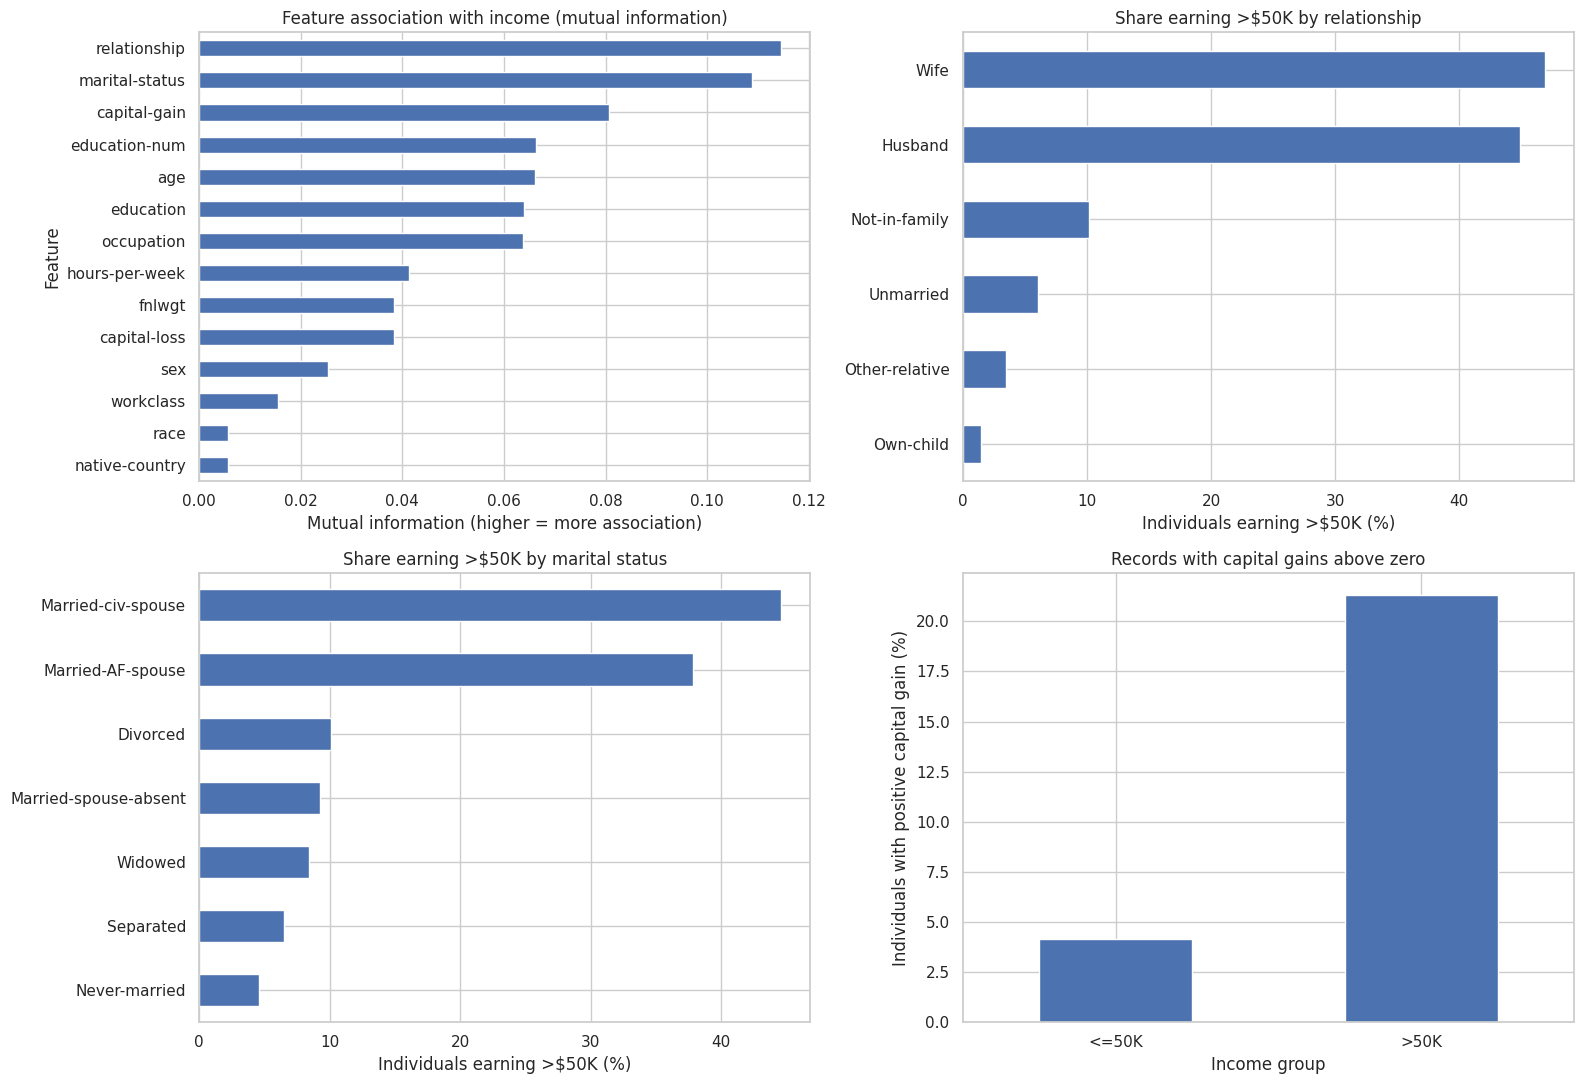

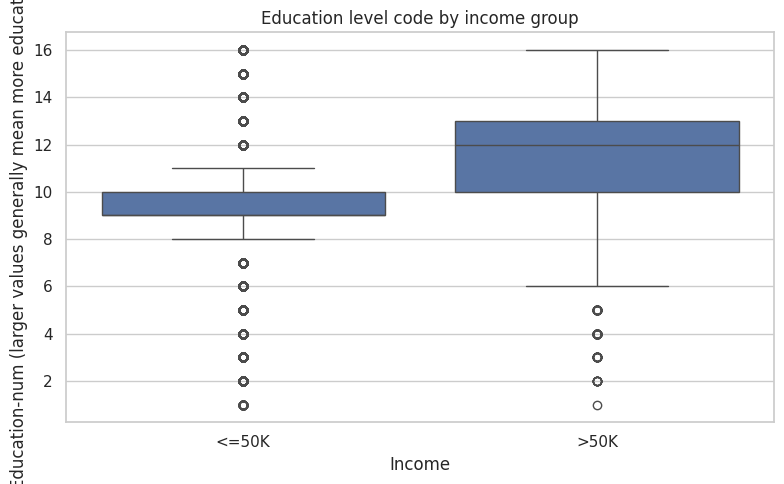

In [3]:
# EDA charts: association ranking, categorical income rates, numeric distributions.
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

mi_ranking.sort_values().plot(kind="barh", ax=axes[0, 0])
axes[0, 0].set_title("Feature association with income (mutual information)")
axes[0, 0].set_xlabel("Mutual information (higher = more association)")
axes[0, 0].set_ylabel("Feature")

rel_rates = df.groupby("relationship")["income"].apply(high_income_rate).sort_values()
rel_rates.plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Share earning >$50K by relationship")
axes[0, 1].set_xlabel("Individuals earning >$50K (%)")
axes[0, 1].set_ylabel("")

mar_rates = df.groupby("marital-status")["income"].apply(high_income_rate).sort_values()
mar_rates.plot(kind="barh", ax=axes[1, 0])
axes[1, 0].set_title("Share earning >$50K by marital status")
axes[1, 0].set_xlabel("Individuals earning >$50K (%)")
axes[1, 0].set_ylabel("")

capital_gain_nonzero.sort_index().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Records with capital gains above zero")
axes[1, 1].set_ylabel("Individuals with positive capital gain (%)")
axes[1, 1].set_xlabel("Income group")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="income", y="education-num")
plt.title("Education level code by income group")
plt.xlabel("Income")
plt.ylabel("Education-num (larger values generally mean more education)")
plt.tight_layout()
plt.show()

### Q1 — Suggested written answer

**My three strongest features are `relationship`, `marital-status`, and `capital-gain`, ranked using mutual information and checked against grouped income rates.**

1. **Relationship** — MI is approximately **0.1146**, the largest score in this calculation. Around **44.9%** of records labelled `Husband` and **46.9%** labelled `Wife` are in the >50K group, compared with about **1.5%** for `Own-child`. A person's household relationship can act as a proxy for life stage, household structure, and employment patterns. It does not prove that relationship status causes higher income.
2. **Marital status** — MI is approximately **0.1087**. About **44.6%** of `Married-civ-spouse` records earn >50K, compared with **4.6%** for `Never-married`. These groups may differ in age, work experience, job continuity, and household circumstances. These are associations in this dataset, not causal conclusions.
3. **Capital gain** — MI is approximately **0.0807**. About **21.3%** of the >50K group have capital gains above zero, compared with **4.2%** of the <=50K group. Mean capital gain is approximately **$4,044** for >50K records versus **$147** for <=50K records. Capital gains may reflect investments or assets that tend to be more common among higher-income people. The distribution is highly skewed, and both groups have a median of zero, so the mean alone would be misleading.

**Useful cross-check:** `education-num` is also strongly informative. Its mean is about **11.6** for >50K records and **9.6** for <=50K records. Higher education may be related to access to higher-paying occupations. Relationship and marital status are correlated concepts, however, so for a less redundant three-feature shortlist, I would consider replacing `relationship` with `education-num`.

**Conclusion:** the ranking is data-driven, but it should not be interpreted as proof of causality. Also, mutual-information scores are dependent on the data and estimation settings; they are not percentages.

## Question 2 — Preprocessing pipeline design for regression

### Target and preprocessing decisions

We predict **`hours-per-week`**. All other available columns are predictors, including `income` because it is not the target in this regression problem.

- **Numeric predictors:** fill missing values with the median, then standardize with `StandardScaler`. The median is less sensitive to extreme values than the mean. Scaling puts numeric features on comparable scales and is especially useful for SGD.
- **Categorical predictors:** fill missing values with the most frequent category, then one-hot encode. Categories are labels, so assigning codes like 1, 2, 3 would incorrectly imply an order. `handle_unknown="ignore"` allows the pipeline to handle categories that appear in test data but not training data.
- **Split before fitting:** imputation, scaling, and encoding are fitted within the training data by the pipeline. This avoids learning preprocessing statistics from the test set.

In [4]:
def make_preprocessor(categorical_cols, numeric_cols):
    """Build preprocessing branches for categorical and numeric predictors."""
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

# Regression dataset: the target is hours-per-week, not income.
X_reg = df.drop(columns=["hours-per-week"])
y_reg = df["hours-per-week"]
cat_reg = X_reg.select_dtypes(include="object").columns.tolist()
num_reg = X_reg.select_dtypes(include=np.number).columns.tolist()

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

reg_preprocessor = make_preprocessor(cat_reg, num_reg)
print("Target:", "hours-per-week")
print("Numeric columns:", num_reg)
print("Categorical columns:", cat_reg)
print("Training rows:", len(X_reg_train), "| Test rows:", len(X_reg_test))

Target: hours-per-week
Numeric columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']
Training rows: 39032 | Test rows: 9758


### Why use a pipeline?

A pipeline bundles cleaning and modeling into one reproducible object. When `fit()` is called, the imputer and scaler learn from the training data only; at prediction time, exactly the same transformations are applied to the test data. This reduces accidental inconsistency and data leakage.

## Question 3 — Regression modeling and evaluation

We will compare two estimators with the same preprocessing:

- **Linear Regression** estimates coefficients to minimize squared prediction errors.
- **SGD Regressor** learns a linear model through repeated gradient-based updates. It can scale to large datasets and benefits from standardized numeric inputs.

Metric interpretation:
- **R²:** closer to 1 is better; 0 means no better than predicting the target mean (under the standard definition).
- **MAE:** average absolute error, measured here in hours per week.
- **MSE:** average squared error, which penalizes large mistakes more heavily.

In [5]:
linear_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor(cat_reg, num_reg)),
    ("model", LinearRegression())
])

sgd_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor(cat_reg, num_reg)),
    ("model", SGDRegressor(
        max_iter=3000, tol=1e-3, random_state=RANDOM_STATE,
        learning_rate="adaptive", eta0=0.01, penalty="l2"
    ))
])

regression_results = []
for model_name, model in [("Linear Regression", linear_model), ("SGD Regressor", sgd_model)]:
    model.fit(X_reg_train, y_reg_train)
    pred = model.predict(X_reg_test)
    regression_results.append({
        "Model": model_name,
        "R2": r2_score(y_reg_test, pred),
        "MAE_hours": mean_absolute_error(y_reg_test, pred),
        "MSE": mean_squared_error(y_reg_test, pred),
        "RMSE_hours": mean_squared_error(y_reg_test, pred) ** 0.5
    })

regression_results = pd.DataFrame(regression_results).set_index("Model")
display(regression_results.round(4))

,R2,MAE_hours,MSE,RMSE_hours
Model,,,,
Linear Regression,0.1675,7.7230,123.547,11.1152
SGD Regressor,0.1679,7.7208,123.489,11.1126


### Q3 — Interpretation

On this split, the **SGD Regressor is very slightly better**: R² is about **0.1679**, MAE is about **7.72 hours**, and MSE is about **123.49**. Linear Regression has R² about **0.1675**, MAE about **7.72 hours**, and MSE about **123.55**.

The difference is tiny, so in practical terms these models are nearly tied. R² around 0.17 also means the models explain only a modest share of the variation in weekly work hours. More complex/nonlinear models or additional useful features might help, but they would need evaluation rather than assumption.

## Question 4 — Logistic Regression classification pipeline and error analysis

Now the target is **`income`**. We encode the positive class `>50K` as 1 and `<=50K` as 0.

We use a stratified split so the train and test sets retain similar class proportions. All predictors are the columns other than `income`; we must not feed the answer itself into the classifier. The same imputation, scaling, and one-hot encoding logic is used, followed by Logistic Regression.

- **Accuracy:** fraction of all predictions that are correct.
- **Precision for >50K:** among people predicted >50K, how many truly are >50K?
- **Recall for >50K:** among all actual >50K people, how many did the model identify?
- **Confusion matrix:** helps identify false positives and false negatives.

In [6]:
X_cls = df.drop(columns=["income"])
y_cls = (df["income"] == ">50K").astype(int)
cat_cls = X_cls.select_dtypes(include="object").columns.tolist()
num_cls = X_cls.select_dtypes(include=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X_cls, y_cls, test_size=0.20, random_state=RANDOM_STATE, stratify=y_cls
)

logistic_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor(cat_cls, num_cls)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
logistic_model.fit(X_train, y_train)
y_pred_logistic = logistic_model.predict(X_test)

logistic_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_logistic),
    "Precision (>50K)": precision_score(y_test, y_pred_logistic, zero_division=0),
    "Recall (>50K)": recall_score(y_test, y_pred_logistic, zero_division=0)
}
display(pd.Series(logistic_metrics, name="Logistic Regression").to_frame().round(4))

cm_logistic = confusion_matrix(y_test, y_pred_logistic, labels=[0, 1])
print("Confusion matrix (rows = actual [<=50K, >50K], columns = predicted [<=50K, >50K]):")
display(pd.DataFrame(cm_logistic,
                     index=["Actual <=50K", "Actual >50K"],
                     columns=["Predicted <=50K", "Predicted >50K"]))

print("Classification report:")
print(classification_report(y_test, y_pred_logistic, target_names=["<=50K", ">50K"], digits=4))

,Logistic Regression
Accuracy,0.8520
Precision (>50K),0.7304
Recall (>50K),0.6053


Confusion matrix (rows = actual [<=50K, >50K], columns = predicted [<=50K, >50K]):


,Predicted <=50K,Predicted >50K
Actual <=50K,6900,522
Actual >50K,922,1414


Classification report:
              precision    recall  f1-score   support

       <=50K     0.8821    0.9297    0.9053      7422
        >50K     0.7304    0.6053    0.6620      2336

    accuracy                         0.8520      9758
   macro avg     0.8062    0.7675    0.7836      9758
weighted avg     0.8458    0.8520    0.8470      9758



### Q4 — Interpretation and error analysis

Expected result on this split: about **85.20% accuracy**, **73.04% precision**, and **60.53% recall** for the >50K class.

The confusion matrix is approximately:

| | Predicted <=50K | Predicted >50K |
|---|---:|---:|
| Actual <=50K | 6,900 | 522 |
| Actual >50K | 922 | 1,414 |

- **True negatives (6,900):** lower-income records correctly identified.
- **False positives (522):** lower-income records incorrectly predicted as >50K.
- **False negatives (922):** higher-income records missed by the model.
- **True positives (1,414):** higher-income records correctly identified.

The model's precision is stronger than its recall. It is reasonably selective when predicting >50K, but it still misses about 39.5% of the actual >50K class at the default 0.5 probability threshold. Whether to increase recall depends on the cost of missing a positive case versus making a false positive; classification thresholds can be tuned if the assignment permits.

## Question 5 — Tune KNN with GridSearchCV and compare it with Logistic Regression

K-Nearest Neighbors predicts a class using the labels of nearby training examples. It is distance-based, so scaling the numeric features is important.

We tune:
- `n_neighbors`: how many neighbors vote.
- `weights`: whether all neighbors vote equally (`uniform`) or closer neighbors count more (`distance`).
- `metric`: the distance function (`euclidean` or `manhattan`).

**Runtime note:** KNN searches can be expensive because predictions compare examples with many training rows. To keep this practice notebook quick, hyperparameter selection uses a stratified 2,000-row subset of the training split with 3-fold cross-validation. The selected KNN configuration is then re-fit on the **full training split** and tested against the same test set as Logistic Regression. For an exhaustive search, replace the tuning-subset variables with the entire training set, accepting longer runtime.

In [7]:
# Use a stratified subset only for hyperparameter selection to keep GridSearchCV manageable.
X_grid, _, y_grid, _ = train_test_split(
    X_train, y_train, train_size=2000,
    random_state=RANDOM_STATE, stratify=y_train
)

knn_pipeline_for_search = Pipeline(steps=[
    ("preprocessor", make_preprocessor(cat_cls, num_cls)),
    ("model", KNeighborsClassifier(algorithm="brute", n_jobs=1))
])

param_grid = {
    "model__n_neighbors": [5, 11, 21],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline_for_search,
    param_grid=param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=1,
    refit=False,
    verbose=1
)
grid_search.fit(X_grid, y_grid)

print("Best cross-validation accuracy on tuning subset:", round(grid_search.best_score_, 4))
print("Best hyperparameters:", grid_search.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


Best cross-validation accuracy on tuning subset: 0.8485
Best hyperparameters: {'model__metric': 'manhattan', 'model__n_neighbors': 21, 'model__weights': 'uniform'}


In [8]:
# Refit selected hyperparameters on the full training split.
best_knn_params = {key.replace("model__", ""): value
                   for key, value in grid_search.best_params_.items()}

knn_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor(cat_cls, num_cls)),
    ("model", KNeighborsClassifier(algorithm="brute", n_jobs=1, **best_knn_params))
])
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

knn_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_knn),
    "Precision (>50K)": precision_score(y_test, y_pred_knn, zero_division=0),
    "Recall (>50K)": recall_score(y_test, y_pred_knn, zero_division=0)
}

comparison = pd.DataFrame({
    "Logistic Regression": logistic_metrics,
    "Tuned KNN": knn_metrics
})
display(comparison.round(4))

print("KNN confusion matrix (rows = actual [<=50K, >50K], columns = predicted [<=50K, >50K]):")
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])
display(pd.DataFrame(cm_knn,
                     index=["Actual <=50K", "Actual >50K"],
                     columns=["Predicted <=50K", "Predicted >50K"]))

,Logistic Regression,Tuned KNN
Accuracy,0.8520,0.8469
Precision (>50K),0.7304,0.7076
Recall (>50K),0.6053,0.6143


KNN confusion matrix (rows = actual [<=50K, >50K], columns = predicted [<=50K, >50K]):


,Predicted <=50K,Predicted >50K
Actual <=50K,6829,593
Actual >50K,901,1435


### Q5 — Comparison and conclusion

For this run, GridSearchCV selects approximately:

- `n_neighbors = 21`
- `weights = 'uniform'`
- `metric = 'manhattan'`

On the held-out test set, tuned KNN reaches about **84.69% accuracy**, **70.76% precision**, and **61.43% recall**. Logistic Regression reaches about **85.20% accuracy**, **73.04% precision**, and **60.53% recall**.

**Overall, Logistic Regression is slightly better** for accuracy and precision, while KNN is slightly better for recall. The differences are not huge. KNN does not outperform Logistic Regression across all metrics, even after tuning. This is a valid result: tuning helps find a good KNN configuration, but it cannot guarantee that KNN will beat another algorithm.

### Final lessons

1. Clean inconsistent labels and missing-value markers before analysis.
2. Use charts plus statistics rather than relying on intuition alone.
3. Fit preprocessing inside a pipeline to keep train/test handling consistent.
4. Use more than accuracy when the classes are imbalanced.
5. Use the same test split and positive-class definition when comparing classifiers.
6. Explain what the metric means in context, and do not confuse association with causation.